Model Train data  MAE  RMSE  MAPE %
 LSTM        raw 3.88  4.66   24.32
 LSTM   filtered 4.25  5.46   26.65


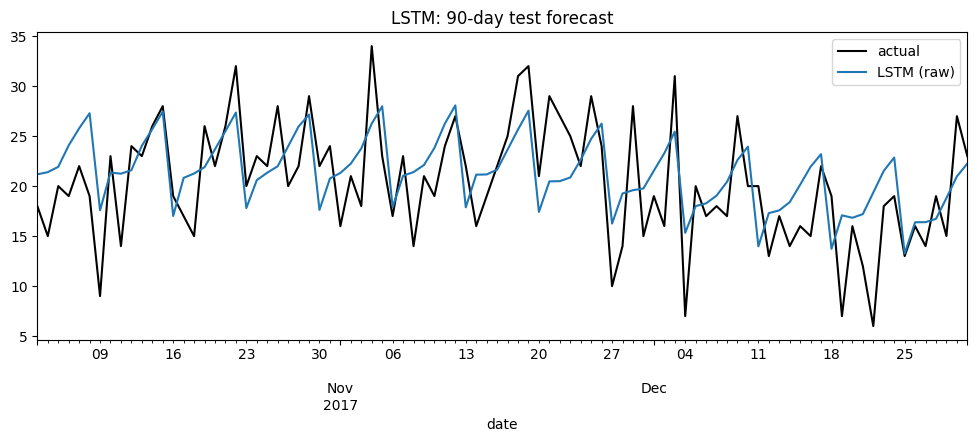

In [6]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import torch, torch.nn as nn

rd = lambda f: pd.read_csv(f"../data/{f}", parse_dates=["date"], index_col="date")["sales"].asfreq("D")
train_raw, train_f, test = rd("train_raw.csv"), rd("train_filtered.csv"), rd("test_raw.csv")
W, H = 56, len(test)  # 56-day input window, 90-day output

def metrics(y, p):
    return (np.mean(np.abs(y-p)), np.sqrt(np.mean((y-p)**2)), np.mean(np.abs((y-p)/y))*100)

def feats(idx, y):
    dow, doy = idx.dayofweek.values, idx.dayofyear.values
    return np.column_stack([y,
        np.sin(2*np.pi*dow/7), np.cos(2*np.pi*dow/7),
        np.sin(2*np.pi*doy/365.25), np.cos(2*np.pi*doy/365.25)]).astype("float32")

class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(5, 64, batch_first=True)
        self.fc = nn.Linear(64, H)
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1])

def lstm_forecast(train, seeds=(0, 1, 2), epochs=60):
    mu, sd = train.mean(), train.std()
    y = ((train.values - mu) / sd).astype("float32")
    F = feats(train.index, y)
    X = np.stack([F[i-W:i] for i in range(W, len(y)-H+1)])
    Y = np.stack([y[i:i+H] for i in range(W, len(y)-H+1)])
    X, Y = torch.tensor(X), torch.tensor(Y)
    last = torch.tensor(F[-W:]).unsqueeze(0)
    preds = []
    for s in seeds:
        torch.manual_seed(s)
        net = Net(); opt = torch.optim.Adam(net.parameters(), lr=1e-3, weight_decay=1e-5)
        for ep in range(epochs):
            perm = torch.randperm(len(X))
            for i in range(0, len(X), 64):
                b = perm[i:i+64]
                opt.zero_grad()
                loss = nn.functional.mse_loss(net(X[b]), Y[b])
                loss.backward(); opt.step()
        net.eval()
        with torch.no_grad():
            preds.append(net(last).squeeze(0).numpy())
    p = np.mean(preds, axis=0) * sd + mu   # average of 3 seeds
    return np.clip(p, 0, None)

rows, out = [], {}
for tname, tr in {"raw": train_raw, "filtered": train_f}.items():
    p = lstm_forecast(tr)
    out[f"LSTM ({tname})"] = p
    rows.append(["LSTM", tname, *metrics(test.values, p)])

res = pd.DataFrame(rows, columns=["Model","Train data","MAE","RMSE","MAPE %"]).round(2)
print(res.to_string(index=False))

pd.DataFrame(out, index=test.index).to_csv("../outputs/preds_lstm.csv")
res.to_csv("../outputs/results_lstm.csv", index=False)

fig, ax = plt.subplots(figsize=(12, 4))
test.plot(ax=ax, color="black", label="actual")
pd.Series(out["LSTM (raw)"], index=test.index).plot(ax=ax, label="LSTM (raw)")
ax.legend(); ax.set_title("LSTM: 90-day test forecast")
plt.savefig("../outputs/07_lstm.png", dpi=150)